# Module 00: Math with Python and Notation

ML papers and textbooks are written in a compact symbolic language. Most of the "math is hard" feeling comes from
**not being fluent in the notation**, not from the ideas themselves. This module is a phrasebook: every symbol you'll
meet is translated into Python you already know.

**Learning goals**
- Read Σ, Π, ∈, ℝⁿ, x⁽ⁱ⁾ vs xᵢ, ŷ, ‖x‖, argmin, ∀, ∃, :=, ∝ fluently
- Translate formulas into NumPy, as loops first and then vectorized
- Use SymPy as a "calculator for algebra" to check your pen-and-paper work
- Know the floating-point traps that break ML code (and how to compare floats safely)

In [1]:
# Standard setup: make the repo root importable, load the usual tools, fix the random seed.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # notebooks live in modules/XX_name/, so go up two levels
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from common.checks import check
from common import plotting as mplt

sp.init_printing()                         # pretty-print SymPy results as math
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)            # use rng.normal(...), rng.integers(...) for reproducible randomness

## 1. The notation phrasebook

| Symbol | Read as | Python |
|---|---|---|
| $x \in \mathbb{R}$ | "x is a real number" | `x = 3.7` |
| $\mathbf{x} \in \mathbb{R}^n$ | "x is a vector of n reals" | `x.shape == (n,)` |
| $X \in \mathbb{R}^{m \times n}$ | "X is an m-by-n matrix" | `X.shape == (m, n)` |
| $x_i$ | "the i-th component of x" | `x[i]` (math usually counts from 1!) |
| $\mathbf{x}^{(i)}$ | "the i-th **example**" (the superscript is not a power) | `X[i]`, a row of the data matrix |
| $x_j^{(i)}$ | "feature j of example i" | `X[i, j]` |
| $\sum_{i=1}^{n} a_i$ | "sum of a_i for i from 1 to n" | `a.sum()` |
| $\prod_{i=1}^{n} a_i$ | "product of a_i" | `a.prod()` |
| $\hat{y}$ | "y-hat": a **prediction** of y | `y_hat = model(x)` |
| $\bar{x}$ | "x-bar": the mean | `x.mean()` |
| $\lVert \mathbf{x} \rVert$ | "norm (length) of x" | `np.linalg.norm(x)` |
| $\lvert x \rvert$ | absolute value (or the size of a set) | `abs(x)`, `len(s)` |
| $f: \mathbb{R}^n \to \mathbb{R}$ | "f takes an n-vector, returns a number" | `def f(x): return float` |
| $\arg\min_x f(x)$ | "the x that minimizes f" (not the minimum value itself!) | `xs[np.argmin(f(xs))]` |
| $\forall$, $\exists$ | "for all", "there exists" | `all(...)`, `any(...)` |
| $:=$ | "is defined as" | `=` |
| $\propto$ | "is proportional to" (equal up to a constant factor) | n/a |
| $\approx$ | "approximately equal" | `np.isclose(a, b)` |
| $\mathbb{1}[\text{cond}]$ | indicator: 1 if cond is true, else 0 | `(cond).astype(int)` |
| $\mathbb{E}[X]$ | expected value (an average) | `samples.mean()` |
| $\theta$, $w$, $b$ | model **parameters**: weights and bias | `w`, `b` |

The DL-book convention: **lowercase italic** = scalar, **lowercase bold** = vector, **UPPERCASE** = matrix.

## 2. Sums (Σ): the most common symbol in ML

$$\sum_{i=1}^{n} x_i = x_1 + x_2 + \dots + x_n$$

Read it like a `for` loop: the bottom says where the index starts, the top where it stops, the right side what to add.

In [2]:
x = np.array([2.0, 4.0, 6.0, 8.0])

total = 0.0
for i in range(len(x)):     # Σ as a loop (Python counts from 0, the math from 1)
    total += x[i]
print(total, x.sum())        # ...and as one vectorized call

20.0 20.0


Almost every ML formula is a sum. A few you'll see constantly:

| Name | Formula |
|---|---|
| mean | $\bar{x} = \frac{1}{n}\sum_{i=1}^n x_i$ |
| variance | $\sigma^2 = \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2$ |
| dot product | $\mathbf{w}^\top\mathbf{x} = \sum_{j=1}^d w_j x_j$ |
| mean squared error | $\text{MSE} = \frac{1}{n}\sum_{i=1}^n (y^{(i)} - \hat{y}^{(i)})^2$ |

The trick to translating: **find the index, find the range, and vectorize whatever is inside.**

In [3]:
y     = np.array([3.0, 5.0, 7.0])
y_hat = np.array([2.5, 5.0, 8.0])

mse_loop = sum((y[i] - y_hat[i]) ** 2 for i in range(len(y))) / len(y)
mse_vec = np.mean((y - y_hat) ** 2)            # same thing: subtract, square, average
print(mse_loop, mse_vec)

0.4166666666666667 0.4166666666666667


### Nested sums and the data matrix
A data matrix $X$ has one row per example and one column per feature. A double sum
$\sum_{i=1}^{m}\sum_{j=1}^{n} X_{ij}$ visits every cell. A sum over **one** index collapses **one** axis:

- $\sum_i X_{ij}$ (sum over examples) → one number per feature → `X.sum(axis=0)`
- $\sum_j X_{ij}$ (sum over features) → one number per example → `X.sum(axis=1)`

In [4]:
X = np.arange(1, 7).reshape(2, 3)   # 2 examples, 3 features
print(X)
print("all:", X.sum(), "| per feature:", X.sum(axis=0), "| per example:", X.sum(axis=1))

[[1 2 3]
 [4 5 6]]
all: 21 | per feature: [5 7 9] | per example: [ 6 15]


### Sum rules worth memorizing
1. Constants come out: $\sum_i c\,a_i = c\sum_i a_i$
2. Sums split: $\sum_i (a_i + b_i) = \sum_i a_i + \sum_i b_i$
3. Summing a constant: $\sum_{i=1}^n c = n c$
4. Products **don't** split: $\sum_i a_i b_i \ne (\sum_i a_i)(\sum_i b_i)$

Rules 1–3 are what make "linearity" arguments work in later modules.

In [5]:
a, b, c = rng.normal(size=5), rng.normal(size=5), 3.0
print(np.isclose((c * a).sum(), c * a.sum()),
      np.isclose((a + b).sum(), a.sum() + b.sum()),
      np.isclose((a * b).sum(), a.sum() * b.sum()))   # the last one is False

True True False


## 3. Products (Π) and why we take logs
$$\prod_{i=1}^n p_i = p_1 \cdot p_2 \cdots p_n$$
In ML, Π usually shows up as a **likelihood**: the probability of the whole dataset is the product of the
probabilities of each example. Multiplying many numbers below 1 quickly underflows to 0.0, so we take logs and
turn the product into a sum: $\log \prod_i p_i = \sum_i \log p_i$. Module 01 covers this in depth.

In [6]:
p = np.full(1000, 0.5)      # 1000 examples, each predicted with probability 0.5
print("product:", p.prod())          # underflows to 0.0
print("log of product as a sum:", np.log(p).sum())   # perfectly fine: -693.1

product: 9.332636185032189e-302
log of product as a sum: -693.1471805599454


## 4. argmin / argmax and the indicator function
$\min_x f(x)$ is the smallest **value**. $\arg\min_x f(x)$ is **where** it happens. Training a model is
$\theta^* = \arg\min_\theta \text{Loss}(\theta)$: we want the parameters, not the loss value.

In [7]:
xs = np.linspace(-3, 5, 801)
f = (xs - 1.5) ** 2 + 2
print("min f =", f.min(), "  argmin x =", xs[np.argmin(f)])

min f = 2.0   argmin x = 1.5


The indicator $\mathbb{1}[\cdot]$ turns a condition into 0/1. Accuracy is just an average of indicators:
$$\text{accuracy} = \frac{1}{n}\sum_{i=1}^n \mathbb{1}[\hat{y}^{(i)} = y^{(i)}]$$

In [8]:
y_true = np.array([1, 0, 1, 1, 0])
y_pred = np.array([1, 0, 0, 1, 1])
print("accuracy:", np.mean(y_true == y_pred))   # a boolean array averages as 0/1

accuracy: 0.6


## 5. Functions, and plotting them
$f: \mathbb{R} \to \mathbb{R}$ is a machine: number in, number out. Write NumPy functions so they work on whole
arrays, so you can evaluate and plot them on a grid in one line.

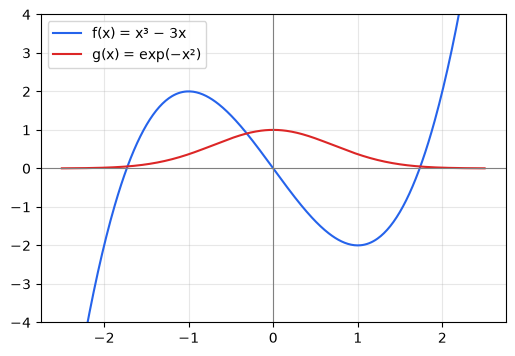

In [9]:
def f(x):
    return x ** 3 - 3 * x

def g(x):
    return np.exp(-x ** 2)

mplt.plot_function([f, g], -2.5, 2.5, labels=["f(x) = x³ − 3x", "g(x) = exp(−x²)"], ylim=(-4, 4))
plt.show()

A function of **two** variables, $f: \mathbb{R}^2 \to \mathbb{R}$, is a surface. The usual picture is a **contour
plot**: a topographic map where each line joins points with equal height. Loss surfaces look like this.

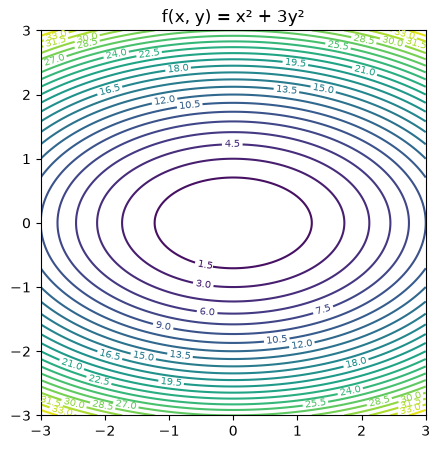

In [10]:
mplt.plot_contour_with_path(lambda x, y: x**2 + 3 * y**2, title="f(x, y) = x² + 3y²")
plt.show()

## 6. SymPy: a calculator for algebra
NumPy computes with **numbers**. SymPy manipulates **symbols**, like doing algebra on paper. Use it to check your
✍️ work: expand, simplify, solve, and (from module 09) differentiate.

In [11]:
x, y = sp.symbols("x y")
expr = (x + 1) ** 2 - (x - 1) ** 2
expr

In [12]:
sp.expand(expr)            # 4x: the squares cancel

In [13]:
sp.simplify((x**2 - 1) / (x - 1))   # x + 1

In [14]:
sp.solve(sp.Eq(x**2 - 5 * x + 6, 0), x)   # roots of a quadratic

In [15]:
sp.solve([sp.Eq(2 * x + y, 5), sp.Eq(x - y, 1)], [x, y])   # a 2×2 linear system (module 04 does these by hand)

In [16]:
expr2 = x**2 + 3 * x
print(expr2.subs(x, 2))                 # plug in a value
f_num = sp.lambdify(x, expr2, "numpy")  # symbolic expression -> fast NumPy function
f_num(np.array([0.0, 1.0, 2.0]))

10


array([ 0.,  4., 10.])

SymPy also knows sums in closed form, e.g. $\sum_{i=1}^n i = \frac{n(n+1)}{2}$:

In [17]:
i, n = sp.symbols("i n", integer=True, positive=True)
sp.factor(sp.summation(i, (i, 1, n))), sp.factor(sp.summation(i**2, (i, 1, n)))

## 7. Floating point: computers don't do real numbers
A float64 stores about 16 significant digits. That leads to four traps that show up in real ML code.

### Trap 1: rounding means `==` is unreliable

In [18]:
print(0.1 + 0.2 == 0.3, 0.1 + 0.2)
print(np.isclose(0.1 + 0.2, 0.3))        # compare floats with a tolerance instead
print(np.finfo(np.float64).eps, np.finfo(np.float32).eps)   # machine epsilon: the gap between 1 and the next float

False 0.30000000000000004
True
2.220446049250313e-16 1.1920929e-07


float32 (what GPUs use) has only about 7 digits. That is why deep learning code uses tolerances like `1e-5`.

### Trap 2: overflow, where numbers get too big

In [19]:
with np.errstate(over="ignore"):
    print(np.exp(np.array([100.0, 710.0])))    # exp(710) overflows to inf in float64
    print(np.exp(np.float32(89.0)))             # float32 overflows much earlier

[2.6881e+43        inf]
inf


### Trap 3: underflow, where numbers get too small
We saw this with products of probabilities in section 3. The fix is the same: work in log space.

In [20]:
print(np.exp(-800.0), 1e-200 * 1e-200)

0.0 0.0


### Trap 4: catastrophic cancellation
Subtracting two nearly equal numbers wipes out the significant digits. Mathematically, ((1 + 10⁻¹²) − 1) / 10⁻¹² = 1 exactly.

In [21]:
big = 1.0 + 1e-12
print((big - 1.0) / 1e-12)     # should be 1.0, but we get 1.000088900582341

1.000088900582341


NaN ("not a number") comes from things like `0/0`, `inf - inf`, or `log` of a negative number. It is contagious:
one NaN in a loss makes everything NaN. `np.isnan(...).any()` is a standard debugging check.

In [22]:
with np.errstate(invalid="ignore", divide="ignore"):
    bad = np.array([1.0, 0.0]) / np.array([1.0, 0.0])
print(bad, np.isnan(bad).any(), np.nan == np.nan)   # NaN is not even equal to itself!

[ 1. nan] True False


## Where you'll use this
- **Everywhere.** Every paper and every later module uses this notation.
- Σ-to-NumPy translation is the core skill in ML course modules 07–08 (losses and metrics) and DL module 01 (MLP).
- Log-space computation and float32 tolerances come back in module 01 (log-sum-exp) and DL module 04 (training loop).

## Summary
- Σ is a loop and `.sum(axis=...)` vectorizes it. Π becomes Σ after taking logs.
- x⁽ⁱ⁾ is example i (a row), xⱼ is feature j (a column), and ŷ is a prediction.
- argmin returns *where* the minimum is, not its value.
- SymPy checks algebra; NumPy computes numbers.
- Never compare floats with `==`. Watch for overflow, underflow, cancellation and NaN.

## 📚 Recommended videos, books and papers
⭐ = start here. The others are optional, for going deeper.

### 🎥 Videos
- ⭐ [Floating Point Numbers](https://www.youtube.com/watch?v=PZRI1IfStY0) (Computerphile). Why 0.1 + 0.2 != 0.3, in 9 minutes.

### 📘 Books and articles
- ⭐ [Deep Learning, 'Notation' page](https://www.deeplearningbook.org/contents/notation.html) (Goodfellow, Bengio & Courville, 2016). A one-page cheat sheet of the symbols ML papers use. Keep it open while reading the lesson.
- [SymPy introductory tutorial](https://docs.sympy.org/latest/tutorials/intro-tutorial/index.html) (SymPy docs). Go here when you want more symbolic tricks than the lesson shows.

### 📄 Papers
Tip: read the abstract, the figures and the conclusion first, then the method section.

- [What Every Computer Scientist Should Know About Floating-Point Arithmetic](https://docs.oracle.com/cd/E19957-01/806-3568/ncg_goldberg.html) (Goldberg, 1991). The classic reference. Skim the first section on rounding error. The rest is for reference.